# Simulators and tolerances: what makes synthetic radar data useful

**Question.** Synthetic range-Doppler (RD) data trains a detector that is tested on real data. Which properties of the
synthetic data decide how well that works, and are they the same on different radars?

**Three radars.** CARRADA (TI AWR1843, static, test track, 256 x 64), RADDet (same chip, static, street, 256 x 64),
RADIal (12-Tx DDMA radar on a moving car, 512 x 256).

**Protocol** (docs/notes/2026-11-02-simulators.md, docs/notes/2026-11-02-study2b.md). One small U-Net heatmap detector,
trained on 200 synthetic sequences (8 frames each) only, 3 seeds, scored on real test data: AP@2 (a detection
matches a label within 2 cells; primary), AP@4, recall@2. The 50 real training sequences tune the simulators
and nothing else; 32 real val sequences early-stop training; the **whole val split decides** every choice; test is
only reported. RADDet uses a scene-disjoint split (its official split interleaves train and test frames of the same scenes).

**What follows.** (1) the data; (2) where the sim-to-real gap is; (3) simulators tuned to each radar, and which fix
matters; (4) what synthetic data is worth in real sequences; (5) tolerance curves: each property pushed from barely
visible to extreme on the best simulator; (6) the insights. Every figure is also written to `results/figures/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

from src import figures as F

## 1. The data: real, spec simulator, tuned simulator

One frame per source (normalised, as the detector sees it; white circles = labels). The **spec simulators** are
built from published radar parameters only. The **tuned simulators** add fixes measured on the 50 real training
sequences (section 3). Rows: CARRADA, RADDet, RADIal; x = Doppler bin, y = range bin (row 0 = nearest).

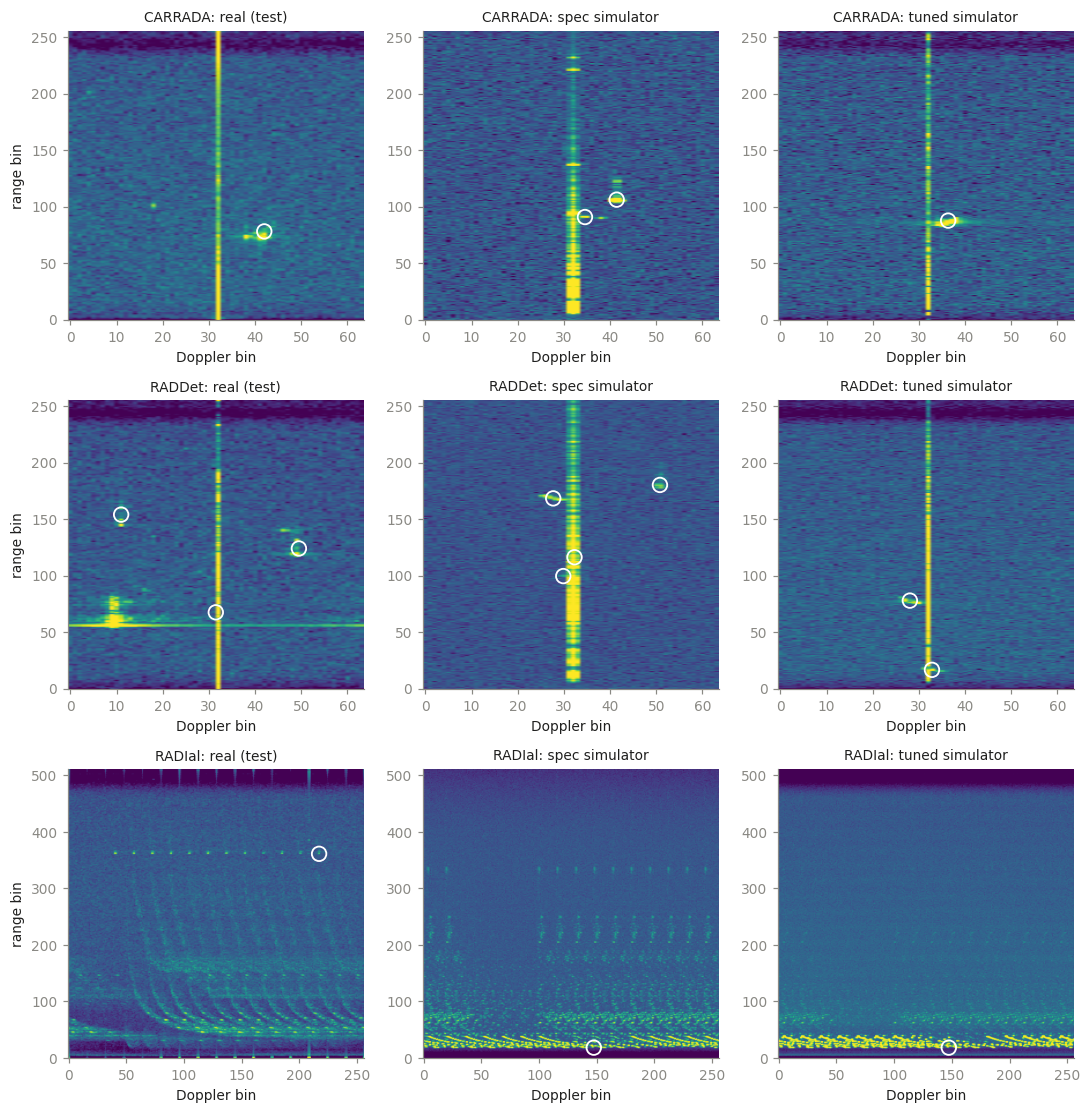

In [2]:
fig = F.maps()
F.save(fig, "maps")

What to see: real CARRADA and RADDet hold the static scene in a single bright zero-Doppler column and darken in
the far rows (receiver filters); the spec simulators spread the column over several bins and have no roll-off.
Real RADIal is full of strong structured clutter out to far range; both simulators are much emptier there.

## 2. Where the sim-to-real gap is

**AP against the match radius.** A detection counts if a label lies within *r* cells. If a gap closes as *r* grows,
the detector finds the objects but puts them away from the labels (localisation, i.e. where labels sit). If it stays,
the detector misses objects or fires on clutter (what the data contains). Black: trained on the 50 real sequences;
dashed: spec simulator; solid colour: best tuned simulator.

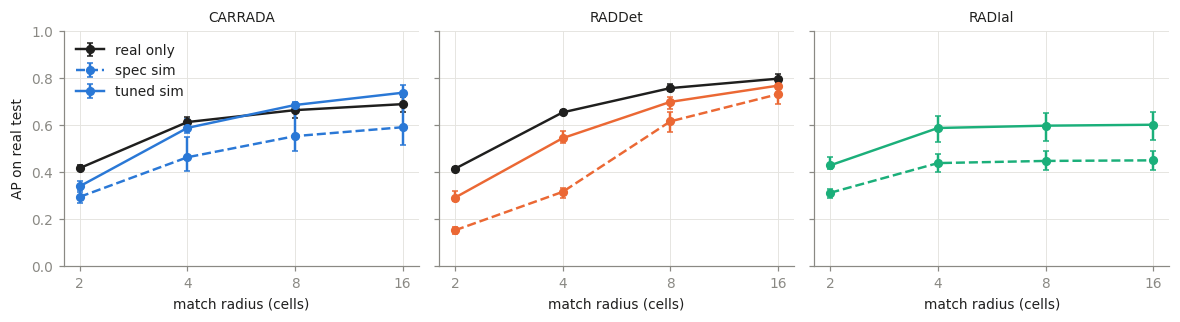

In [3]:
fig = F.radius()
F.save(fig, "radius")

**Where the label sits on the object.** Mean normalised level along range through every label (training
sequences). 0 = the label; + = farther from the radar.

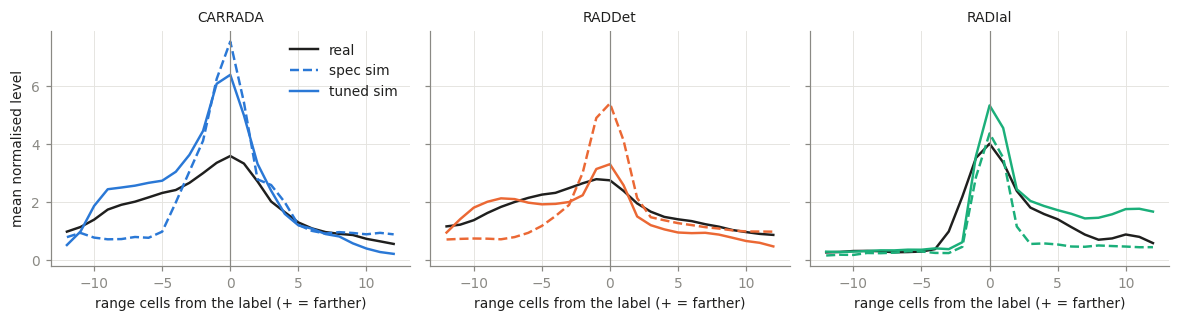

In [4]:
fig = F.label_profile()
F.save(fig, "label_profile")

**Reading.**
- **RADDet: much of the gap was where the label sits.** The spec simulator's gap shrinks steeply with radius. RADDet
  labels the centre of the object's box in the range-angle-Doppler cube; a car's RD energy lies on its near face, in
  front of the label (black curve, left of 0). The spec simulator put its labels on the energy peak (dashed). The tuned
  simulator's labels (centre of the box around the object's returns) follow the real profile.
- **CARRADA and RADIal: what the data contains.** Their gaps stay roughly constant with radius.
- **RADIal: targets have a tail.** Real energy trails several cells behind the label (the car body); the spec
  simulator has none, the tuned one (whole-footprint body scatterers) has one, somewhat too strong.

## 3. Tuned simulators: which fix matters

Fixes (src/tuned.py), each measured on the 50 real training sequences: **processing** (RADDet's FFT windows: Hann in
range, none in Doppler), **range_gain** (per-row level: receiver filters), **scenes** (each sequence starts from a real
training frame's labelled objects), **label** (where labels sit, and only detectable objects labelled), **contrast**
(target strength fitted to the real quartiles), **clutter_profile** (static scene strength per range), **body**
(RADIal: scatterers over the whole vehicle). Each version leaves one fix out ("all-X"). Filled: whole-val AP@2 with
the seed range (decides); hollow: test AP@2 (reported). The best simulator is the highest whole-val mean, a rule
fixed before the runs.

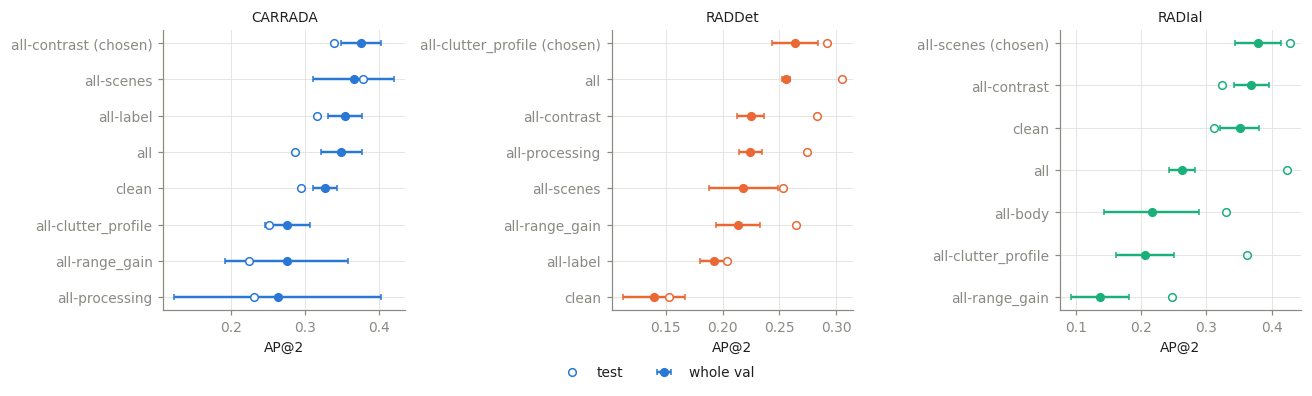

In [5]:
fig = F.ablation()
F.save(fig, "ablation")

In [6]:
F.ablation_table("carrada")

| version | val AP@2 | val range | test AP@2 | test range | test AP@4 | test recall@2 |
|---|---|---|---|---|---|---|
| all-contrast (chosen) | 0.375 | 0.054 | 0.340 | 0.050 | 0.588 | 0.595 |
| all-scenes | 0.366 | 0.110 | 0.379 | 0.074 | 0.615 | 0.661 |
| all-label | 0.354 | 0.045 | 0.316 | 0.076 | 0.558 | 0.608 |
| all | 0.349 | 0.056 | 0.287 | 0.069 | 0.460 | 0.587 |
| clean | 0.327 | 0.032 | 0.295 | 0.055 | 0.463 | 0.677 |
| all-clutter_profile | 0.276 | 0.061 | 0.252 | 0.015 | 0.415 | 0.573 |
| all-range_gain | 0.276 | 0.167 | 0.224 | 0.109 | 0.397 | 0.439 |
| all-processing | 0.263 | 0.279 | 0.232 | 0.340 | 0.405 | 0.546 |

In [7]:
F.ablation_table("raddet")

| version | val AP@2 | val range | test AP@2 | test range | test AP@4 | test recall@2 |
|---|---|---|---|---|---|---|
| all-clutter_profile (chosen) | 0.264 | 0.041 | 0.292 | 0.043 | 0.544 | 0.580 |
| all | 0.256 | 0.007 | 0.305 | 0.010 | 0.559 | 0.593 |
| all-contrast | 0.225 | 0.024 | 0.283 | 0.033 | 0.520 | 0.561 |
| all-processing | 0.225 | 0.020 | 0.274 | 0.042 | 0.561 | 0.553 |
| all-scenes | 0.218 | 0.060 | 0.253 | 0.059 | 0.440 | 0.568 |
| all-range_gain | 0.213 | 0.038 | 0.265 | 0.027 | 0.523 | 0.546 |
| all-label | 0.193 | 0.025 | 0.204 | 0.038 | 0.439 | 0.502 |
| clean | 0.140 | 0.055 | 0.153 | 0.028 | 0.316 | 0.384 |

In [8]:
F.ablation_table("radial")

| version | val AP@2 | val range | test AP@2 | test range | test AP@4 | test recall@2 |
|---|---|---|---|---|---|---|
| all-scenes (chosen) | 0.379 | 0.071 | 0.429 | 0.052 | 0.587 | 0.651 |
| all-contrast | 0.369 | 0.055 | 0.324 | 0.051 | 0.498 | 0.644 |
| clean | 0.351 | 0.061 | 0.312 | 0.041 | 0.438 | 0.677 |
| all | 0.263 | 0.041 | 0.424 | 0.065 | 0.588 | 0.700 |
| all-body | 0.216 | 0.146 | 0.329 | 0.068 | 0.427 | 0.663 |
| all-clutter_profile | 0.205 | 0.089 | 0.362 | 0.096 | 0.494 | 0.624 |
| all-range_gain | 0.136 | 0.090 | 0.247 | 0.003 | 0.381 | 0.508 |

**Reading.**
- **The radar's own processing matters on every radar**: leaving out range gain, and on CARRADA the windows, costs the most.
- **RADDet roughly doubles** from the spec to the tuned simulator; the label convention is the largest single fix.
- **Matching a measured statistic can hurt**: fitting target strength to the real distribution lowers CARRADA (the best
  simulator leaves it out). A first version that matched only the median strength lowered it more, by burying labelled
  objects in noise (docs/notes/2026-11-02-simulators.md).
- **RADIal: val and test disagree** on the full simulator (val falls, test rises). Real scenes drawn from 50 training
  sequences may not represent the val recordings' traffic. Unresolved.

## 4. What synthetic data is worth

Real only vs tuned simulator + real (half of each batch real), against the number of real training sequences
(evenly spaced among the 50). Dotted: the tuned simulator alone.

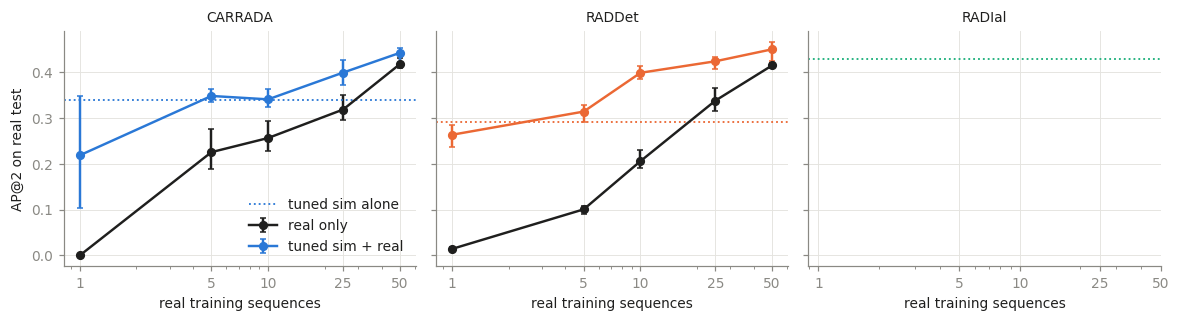

In [9]:
fig = F.budget()
F.save(fig, "budget")

**Reading.** The tuned simulator alone matches roughly 20-25 real sequences. Added to real data it helps most when
real data is scarce, and adds little at 50 sequences.

## 5. Tolerance curves: which differences cost AP

On each radar's best tuned simulator ("clean"), one property is pushed from barely visible to extreme
(Study 2: pre-registered 2026-10-31; Study 2b: the four gaps of section 2, pre-registered 2026-11-02). The y axis is
AP@2 minus clean. **Filled markers: more than that dataset's seed noise below clean** (dotted lines: minus noise).
The **onset** is the mildest level after which every level is filled.

| family | what changes | levels |
|---|---|---|
| blur | target response wider (x) | 1.25 ... 8 |
| sidelobes+ | window sidelobes higher (dB) | +5 ... +20 |
| smoothing | whole map smoothed (%) | 5 ... 90 |
| contrast | targets weaker (dB) | -3 ... -30 |
| noise | targets and scene weaker vs noise (dB) | +3 ... +30 |
| clutter-/+ | static scene weaker / stronger (dB) | 6 ... 20 |
| unrender | objects removed from the map, label kept (%) | 10 ... 90 |
| extra | unlabelled extra objects per sequence (%) | 10 ... 200 |
| rangeshift / dopplershift | every label moved (cells) | 1 ... 8 |
| support | sequences from the simulator's own scenario instead of real labels (%) | 25 ... 100 |
| annotation | objects weaker than threshold + level left unlabelled (dB) | +6 ... +18 |
| tail | target power smeared away from the radar (cells) | 2 ... 16 |
| confusers-/+ | number of poles, parked cars, structures (x) | 0.5, 0 / 2, 4 |

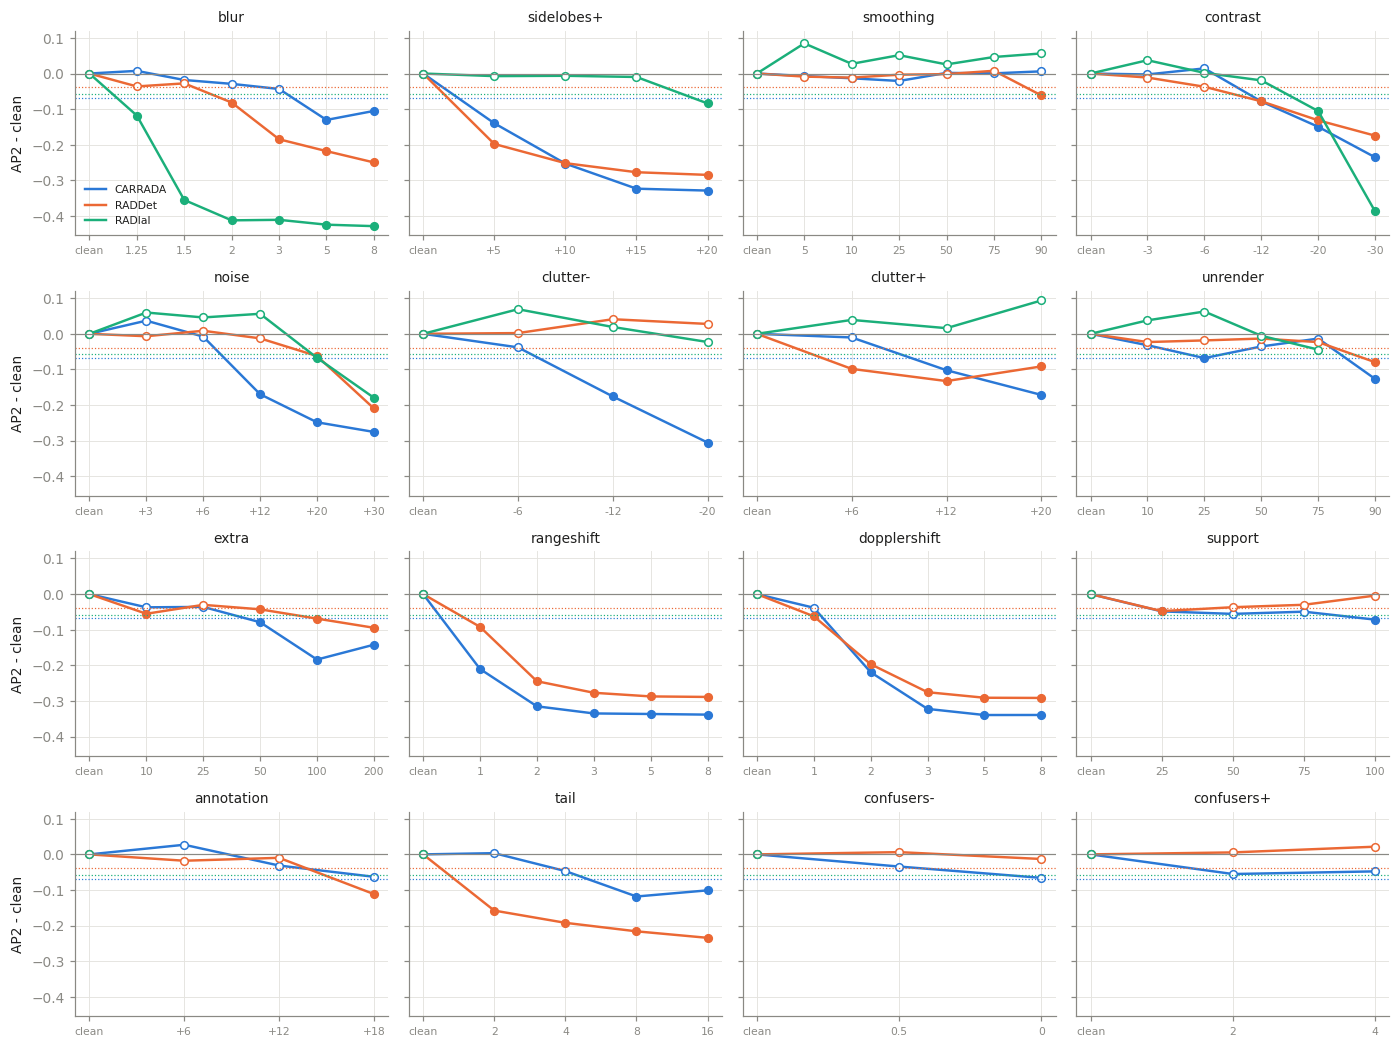

In [10]:
fig = F.tolerance(split="test")
F.save(fig, "tolerance_test")

In [11]:
F.onsets(split="test")

| family | CARRADA | RADDet | RADIal |
|---|---|---|---|
| blur | blur5 | blur2 | blur1.25 |
| sidelobes+ | sidelobes+5 | sidelobes+5 | sidelobes+20 |
| smoothing | None | smoothing90 | None |
| contrast | contrast-12 | contrast-12 | contrast-20 |
| noise | noise+12 | noise+20 | noise+20 |
| clutter- | clutter-12 | None | None |
| clutter+ | clutter+12 | clutter+6 | None |
| unrender | unrender90 | unrender90 | incomplete |
| extra | extra50 | extra50 | incomplete |
| rangeshift | rangeshift1 | rangeshift1 | incomplete |
| dopplershift | dopplershift2 | dopplershift1 | incomplete |
| support | support100 | None | incomplete |
| annotation | None | annotation+18 | incomplete |
| tail | tail8 | tail2 | incomplete |
| confusers- | None | None | incomplete |
| confusers+ | None | None | incomplete |
| (clean AP, noise) | 0.34, 0.07 | 0.29, 0.04 | 0.43, 0.06 |

The same on the whole val split (what choices are made on):

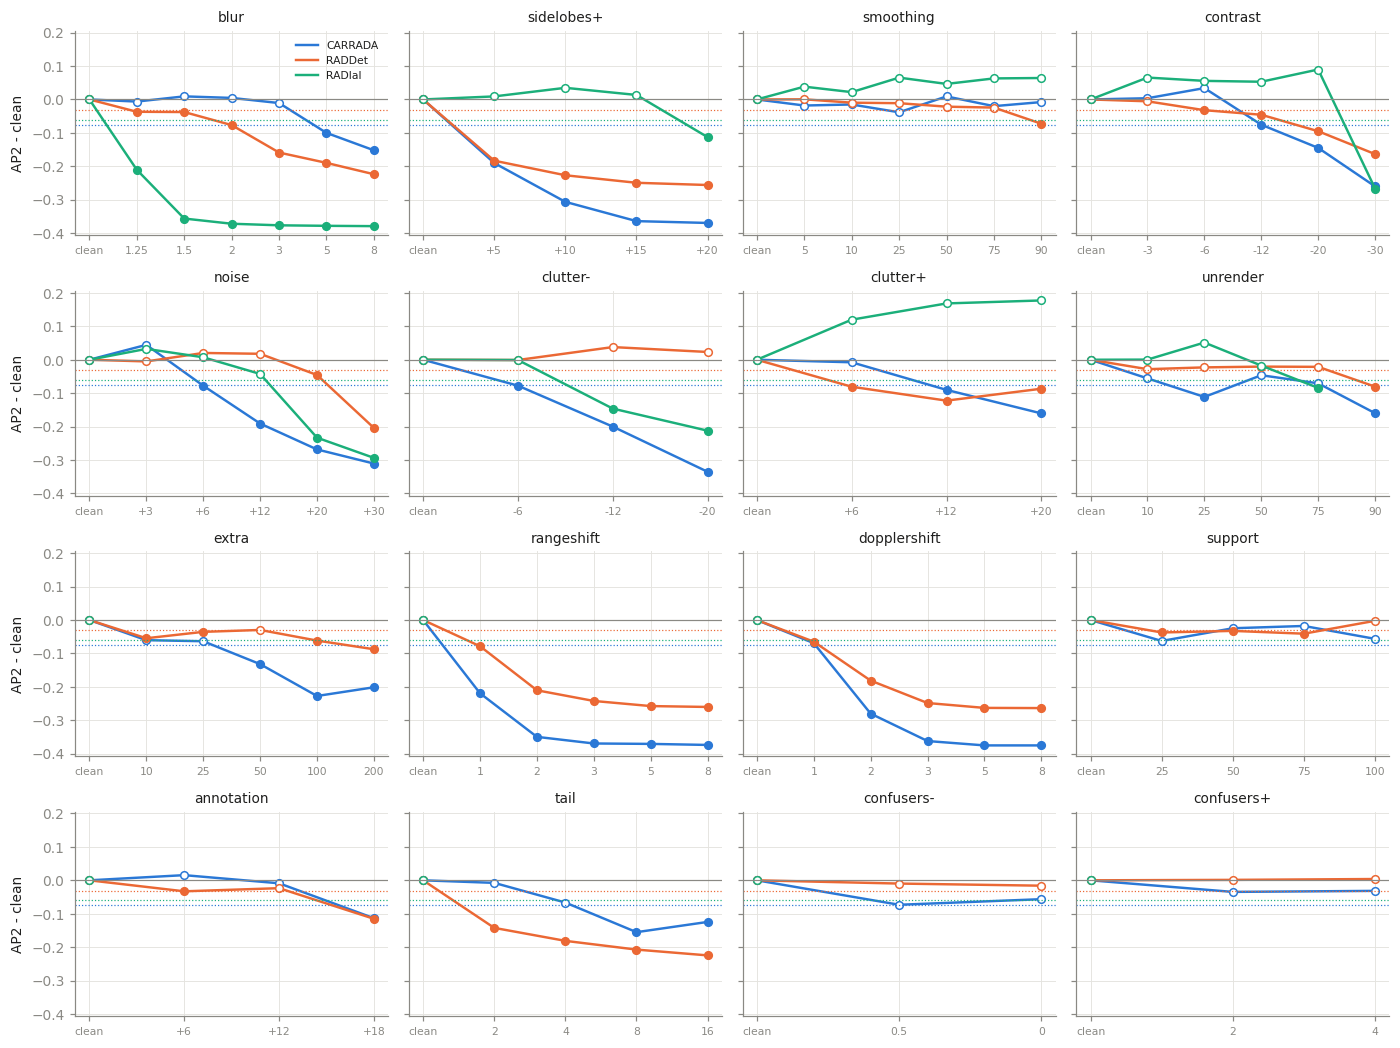

In [12]:
fig = F.tolerance(split="val")
F.save(fig, "tolerance_val")

In [13]:
F.onsets(split="val")

| family | CARRADA | RADDet | RADIal |
|---|---|---|---|
| blur | blur5 | blur1.25 | blur1.25 |
| sidelobes+ | sidelobes+5 | sidelobes+5 | sidelobes+20 |
| smoothing | None | smoothing90 | None |
| contrast | contrast-12 | contrast-6 | contrast-30 |
| noise | noise+6 | noise+20 | noise+20 |
| clutter- | clutter-6 | None | clutter-12 |
| clutter+ | clutter+12 | clutter+6 | None |
| unrender | unrender90 | unrender90 | incomplete |
| extra | extra50 | extra100 | incomplete |
| rangeshift | rangeshift1 | rangeshift1 | incomplete |
| dopplershift | dopplershift2 | dopplershift1 | incomplete |
| support | None | None | incomplete |
| annotation | annotation+18 | annotation+18 | incomplete |
| tail | tail8 | tail2 | incomplete |
| confusers- | None | None | incomplete |
| confusers+ | None | None | incomplete |
| (clean AP, noise) | 0.38, 0.08 | 0.26, 0.03 | 0.38, 0.06 |

**Reading** (RADIal's Study 2 is partly done and its 2b is pending; rerun this notebook when it finishes).
- **Labels cost the most.** One cell of label shift in range already costs AP on CARRADA and RADDet; Doppler shift
  from 1-2 cells. Part of this is the 2-cell match radius, but range shift has its onset at 1 cell with AP@4 too.
- **Target strength and noise are the most consistent families across radars**: onsets between -12 and -20 dB
  weaker targets and +12 to +20 dB noise on all three.
- **Target shape is radar-specific**: RADIal fails at 1.25x blur, RADDet at 2x, CARRADA only at 5x; a range tail
  costs RADDet from 2 cells, CARRADA from 8.
- **Clutter level is radar-specific**: CARRADA loses AP with *less* as well as more clutter; RADDet only with more;
  RADIal with neither so far.
- **Large changes are often harmless**: whole-map smoothing, the number of confusers, where the scenes come from
  (support), and leaving weak objects unlabelled (annotation) barely cost AP.
- **On RADIal, mild damage often helps** (light smoothing, noise, less clutter, weaker targets score above clean).
- **The sidelobe family is not valid for CARRADA and RADDet**: their real processing has no Doppler window, so
  "higher sidelobes" means a degenerate low-attenuation window and even +5 dB is extreme; RADIal (Hamming) tolerates
  up to +20 dB.

## 6. Insights for the paper

1. **Realism is not one number.** Some differences cost AP at once (label position, target strength), others not at
   all over a wide range (smoothing, confusers, scene source). A distance that adds them up cannot rank training sets;
   a useful measure needs per-component tolerances.
2. **Labels are part of the synthetic data.** Where labels sit and which objects get one moved AP more than most
   changes to the maps, and no map-only realism measure can see them.
3. **What matters differs between radars** (target shape on RADDet and RADIal, clutter level on CARRADA), so weights
   must be learned per radar or conditioned on its processing.
4. **More realistic is not always better**: matching measured strength statistics lowered CARRADA; mild damage raised
   RADIal. Utility is not monotonic in realism.
5. **Getting the radar's processing right pays everywhere**, and a tuned simulator is worth about 20-25 real sequences,
   with most of its value when real labels are scarce.

**Caveats.** One detector architecture; 3 seeds (seed noise 0.04-0.07 AP); CARRADA and RADDet share a chip; RADIal's
tolerances are incomplete and its val/test disagree; the tuned simulators replay real label sets, so they are
label-conditioned; candidates are controlled changes of one simulator, not different simulators or generators.